# Step 1 — tag columns that are not features

No outcome or data values are used, only the variable labels.

**Input:** `variable_labels.csv` (from `labels.ipynb`)
**Output:** `feature_catalog.csv` (one row per (module, variable) with category, reason, is_feature) and `step1_counts.txt` (counts per category and features per cycle)

Categories (`is_feature` = False unless noted):

| category | meaning |
|---|---|
| id | SEQN |
| design | survey design / cycle / exam status (kept in the data for weighted analysis) |
| weight | sampling weights (WT*) |
| comment_code | lab / measurement comment or detection-limit codes |
| unit_duplicate | same measurement in another unit (SI) or a text copy of a code |
| process | how the data were collected: interview proxy/interpreter, questionnaire mode, measurement procedure, recall metadata, device info, refused flags (interview language is kept as a feature: acculturation proxy) |
| feature | candidate feature (`is_feature` = True); `long_format` marks files with several rows per person that must be aggregated before use |

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes.paths import WORK  # noqa: E402

## Rules

In [2]:
ORDER = ["2005-06", "2007-08", "2009-10", "2011-12", "2013-14", "2015-16", "2017-18", "2017-20P"]
LONG_FORMAT = {"RXQ_RX", "PAXDAY", "PAQIAF"}

DESIGN = {"SDDSRVYR", "SDMVPSU", "SDMVSTRA", "RIDSTATR"}
PROCESS = {
    # DEMO: interview proxy / interpreter
    "SIAPROXY", "SIAINTRP", "FIAPROXY", "FIAINTRP", "MIAPROXY", "MIAINTRP",
    # questionnaire mode / source flags
    "HSAQUEX", "PAAQUEX", "SMAQUEX", "SMAQUEX2", "DUAISC",
    # body measures / blood pressure procedure
    "BMDSTATS", "BPAARM", "BPACSZ", "BPAEN1", "BPAEN2", "BPAEN3", "BPAEN4", "BPXML1",
    "PEASCST1", "PEASCTM1", "BPQ150A", "BPQ150B", "BPQ150C", "BPQ150D", "BPAOARM", "BPAOCSZ",
    # fasting / OGTT procedure
    "PHAFSTHR", "PHAFSTMN", "GTDBL2MN", "GTDDR1MN", "GTDDR2MN", "GTDSCMMN", "GTXDRANK",
    # dietary recall metadata and refused flags
    "DR1DAY", "DR1DBIH", "DR1DRSTZ", "DR1EXMER", "DR1HELP", "DR1HELPD", "DR1MNRSP",
    "DR1MRESP", "DR2DAY", "DR2DBIH", "DR2DRSTZ", "DR2EXMER", "DR2HELP", "DR2HELPD",
    "DR2MNRSP", "DR2MRESP", "DRDINT", "DRD350K", "DRD370V",
    # accelerometer device / bookkeeping
    "PAXETLDY", "PAXFDAY", "PAXFTIME", "PAXHAND", "PAXLDAY", "PAXORENT", "PAXSENID", "PAXSTS",
    "PAXAISMD", "PAXDAYD", "PAXDAYWD", "PAXMSTD", "PAXSSNDP", "PAXQFD", "PAXTMD",
    # prescription interview; Medicare card shown to the interviewer (asking rule changed 2007)
    "RXQSEEN", "HIQ105",
}
# ALB_CR second-unit columns whose labels do not share a stem with their counterpart
UNIT_DUP_MANUAL = {"URDUCR2S": "URXUCR2", "URDUMA2S": "URXUMA2",
                   "RXDDRUG": "RXDDRGID", "RXDRSD1": "RXDRSC1", "RXDRSD2": "RXDRSC2",
                   "RXDRSD3": "RXDRSC3"}


def stem(label):
    return re.sub(r"\s*\([^)]*\)\s*$", "", label).strip().lower()


def unit_duplicates(cat):
    """{variable: counterpart} for SI / alternate-unit columns sharing a label stem in a module."""
    dup = {}
    for _, g in cat.groupby(["module", cat.label.map(stem)]):
        if len(g) < 2:
            continue
        alt = g[g.variable.str.endswith("SI") | g.variable.isin(["URXCRS", "URXUMS"])]
        base = g[~g.index.isin(alt.index)]
        if len(base) and len(alt):
            for v in alt.variable:
                dup[v] = base.variable.iloc[0]
    return dup


def classify(r, dup):
    v, lab = r.variable, r.label.lower()
    if v == "SEQN":
        return "id", "respondent id"
    if v in DESIGN:
        return "design", "survey design / cycle / exam status"
    if v.startswith("WT"):
        return "weight", "sampling weight"
    if re.search(r"comment|comt code|cmt\. code", lab) or v == "GTDCODE":
        return "comment_code", "comment / detection-limit code"
    if r.module == "COTNAL" and v == "URXUCR":
        return "unit_duplicate", "same value as ALB_CR URXUCR"
    if v in dup:
        return "unit_duplicate", f"same value as {dup[v]}"
    if v in PROCESS:
        return "process", "data-collection process variable"
    return "feature", ""

## Build the catalog

In [3]:
lab = pd.read_csv(WORK / "variable_labels.csv")
cat = (lab.groupby(["module", "variable"])
       .agg(label=("label", "last"),
            cycles=("cycle", lambda s: ",".join(c for c in ORDER if c in set(s))),
            n_cycles=("cycle", "nunique"))
       .reset_index())
dup = {**unit_duplicates(cat), **UNIT_DUP_MANUAL}
cat[["category", "reason"]] = cat.apply(lambda r: pd.Series(classify(r, dup)), axis=1)
cat["is_feature"] = cat.category == "feature"
cat["long_format"] = cat.module.isin(LONG_FORMAT) & cat.is_feature
cat.to_csv(WORK / "feature_catalog.csv", index=False)

lines = ["(module, variable) pairs by category:", cat.category.value_counts().to_string(), ""]
feat = lab.merge(cat[["module", "variable", "is_feature"]], on=["module", "variable"])
rows = []
for c in ORDER:
    d = feat[feat.cycle == c]
    rows.append({"cycle": c, "before": d[d.variable != "SEQN"].variable.nunique(),
                 "after": d[d.is_feature].variable.nunique()})
lines += ["unique variables per cycle (excluding SEQN) before / after step 1:",
          pd.DataFrame(rows).to_string(index=False)]
(WORK / "step1_counts.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

(module, variable) pairs by category:
category
feature           1496
process             74
comment_code        54
id                  49
unit_duplicate      32
weight              22
design               4

unique variables per cycle (excluding SEQN) before / after step 1:
   cycle  before  after
 2005-06    1117   1017
 2007-08    1092    983
 2009-10    1041    931
 2011-12    1089    967
 2013-14    1130   1009
 2015-16    1103   1003
 2017-18     988    892
2017-20P     778    689


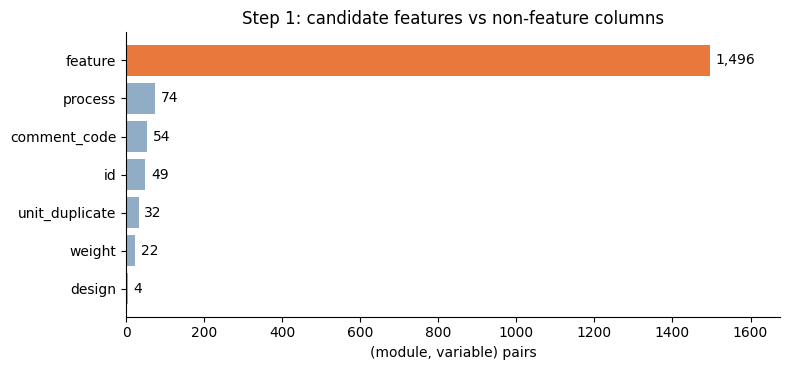

In [4]:
counts = cat.category.value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(counts.index, counts.values, color=["#E9783D" if c == "feature" else "#91ACC5" for c in counts.index])
for i, v in enumerate(counts.values):
    ax.text(v + counts.max() * 0.01, i, f"{v:,}", va="center")
ax.set_xlim(0, counts.max() * 1.12)
ax.set_xlabel("(module, variable) pairs")
ax.set_title("Step 1: candidate features vs non-feature columns")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()